In [1]:
import polars as pl, duckdb, pyarrow, kagglehub
print("Polars:", pl.__version__)
print("DuckDB:", duckdb.__version__)
print("PyArrow:", pyarrow.__version__)

Polars: 2.1.0
DuckDB: 2.0.0
PyArrow: 26.0.1


/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [34]:
import sys
! uv pip install --python {sys.executable} matplotlib
! {sys.executable} -m pip install matplotlib

Using Python 3.12.16 environment at: /usr/local
⠙ contourpy==1.4.0                                                              

Resolved 11 packages in 28ms                                         
error: Failed to install:                                 
       matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl
       (matplotlib==3.11.2)
  cause: Failed to create directory
         `/usr/local/lib/python3.12/site-packages/matplotlib-3.11.2.dist-info`
  cause: failed to create directory
         `/usr/local/lib/python3.12/site-packages/matplotlib-3.11.2.dist-info`:
         Permission denied (os error 13)
Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 35.0 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 45.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 35.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 37.4 MB/s eta 0:00:00

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip instal

In [2]:
! free -h  # RAM
! df -h    # Disco
! pwd      # Carpeta actual

               total        used        free      shared  buff/cache   available
Mem:           7.8Gi       3.2Gi       150Mi        63Mi       4.8Gi       4.5Gi
Swap:             0B          0B          0B
Filesystem      Size  Used Avail Use% Mounted on
overlay          32G  8.7G   22G  30% /
tmpfs            64M     0   64M   0% /dev
shm              64M     0   64M   0% /dev/shm
/dev/sdb1        44G  2.0G   40G   5% /tmp
/dev/root        29G   16G   14G  54% /vscode
/dev/loop4       32G  8.7G   22G  30% /workspaces
tmpfs           4.0K     0  4.0K   0% /proc/acpi
/workspaces/bigdata/proyecto


In [3]:
import os, getpass
os.environ["KAGGLE_API_TOKEN"] = getpass.getpass("Token de Kaggle (KGAT_...): ")
print("Token cargado en esta sesión")

Token cargado en esta sesión


In [4]:
import os, time
os.environ["KAGGLEHUB_CACHE"] = "/tmp/kagglehub"

import kagglehub

inicio = time.time()
ruta_train = kagglehub.competition_download("amex-default-prediction", path="train_data.csv")
ruta_labels = kagglehub.competition_download("amex-default-prediction", path="train_labels.csv")
print(ruta_train)
print(ruta_labels)
print(f"Tiempo de descarga: {time.time() - inicio:.1f} s")

! find /tmp/kagglehub -type f -exec ls -lah {} \;

100%|██████████| 6.67G/6.67G [00:55<00:00, 129MB/s] 

Extracting zip of train_data.csv...


100%|██████████| 16.2M/16.2M [00:00<00:00, 69.5MB/s]

Extracting zip of train_labels.csv...


/tmp/kagglehub/competitions/amex-default-prediction/train_data.csv
/tmp/kagglehub/competitions/amex-default-prediction/train_labels.csv
Tiempo de descarga: 209.2 s
-rw-r--rw- 1 vscode vscode 0 Nov 22 14:39 /tmp/kagglehub/competitions/.complete/amex-default-prediction/train_data.csv.complete
-rw-r--rw- 1 vscode vscode 0 Nov 22 14:39 /tmp/kagglehub/competitions/.complete/amex-default-prediction/train_labels.csv.complete
-rw-r--rw- 1 vscode vscode 30M Nov 22 14:39 /tmp/kagglehub/competitions/amex-default-prediction/train_labels.csv
-rw-r--rw- 1 vscode vscode 16G Nov 22 14:39 /tmp/kagglehub/competitions/amex-default-prediction/train_data.csv


# Predicción de incumplimiento de pago (American Express)

## 1. Entorno y datos
**Entorno:** GitHub Codespaces, 7.8 GiB de RAM (alrededor de 3.9 GiB libres al iniciar) y 40 GB de disco en `/tmp`.

**Dataset:** competencia *American Express - Default Prediction* de Kaggle (50.31 GB en total). Solo dse descargo lo necesario:
- `train_data.csv`: 16 GB, estados de cuenta mensuales de cada cliente.
- `train_labels.csv`: 30 MB, etiqueta de incumplimiento por cliente.

**Optimización 0 (descarga):** no se descargó `test_data.csv` (no tiene etiqueta y pesa alrededor de 33 GB) ni se usó el disco del repo. Los archivos se guardaron en `/tmp` para no llenar `/workspaces` y para que no se suban a GitHub por su limite.

**Resultado:** el zip de 6.67 GB se descargó a unos 134 MB/s; con la extracción, el total fue de alrededor de 3.5 minutos.

## Trabajo
- **Datos:** American Express Default Prediction (Kaggle): `train_data.csv` de 15.27 GiB (≈16 GB) y 5 531 451 filas, en una máquina con ~3.9 GiB de RAM libre.
- **Pregunta:** ¿qué combinación de formato (CSV o Parquet) y motor (Polars o DuckDB) agrega los datos por cliente con menor tiempo y RAM?
- **Respuesta:** Parquet con Polars: 0.81 s y 473 MB frente a 78.01 s y 448 MB con CSV; el formato pesa más que el motor (entre ~77 y ~930 veces).
- **Técnicas de clase:** evaluación perezosa y plan de ejecución, *streaming*, almacenamiento columnar (metadata, grupos de filas, *pushdown*) y estadísticos con datos intermedios.
- **Índice:** 1 Entorno y datos · 2 Exploración · 3 Problema y pregunta · 4 Metodología · 5 a 9 Optimizaciones · 10 Resultados · 11 Conclusiones.

In [5]:
import time, resource
import polars as pl

# Rutas de los archivos descargados (están en /tmp, fuera del repo)
base = "/tmp/kagglehub/competitions/amex-default-prediction"
csv_train = f"{base}/train_data.csv"
csv_labels = f"{base}/train_labels.csv"

def ram_pico_mb():
    # Pico de RAM (RSS máximo) del proceso del notebook, en MB
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024

def medir(nombre, funcion):
    # Ejecuta 'funcion' y reporta el tiempo y el pico de RAM
    ram_antes = ram_pico_mb()
    inicio = time.time()
    resultado = funcion()
    tiempo = time.time() - inicio
    print(f"[{nombre}] tiempo: {tiempo:.2f} s | pico RAM: {ram_pico_mb():.0f} MB (antes: {ram_antes:.0f} MB)")
    return resultado, tiempo

# Prueba: leer solo el esquema (scan_csv es perezoso, no carga el archivo)
esquema, _ = medir("esquema CSV", lambda: pl.scan_csv(csv_train).collect_schema())
print(len(esquema), "columnas")
print(esquema)

[esquema CSV] tiempo: 0.94 s | pico RAM: 338 MB (antes: 338 MB)
190 columnas
Schema({'customer_ID': String, 'S_2': String, 'P_2': Float64, 'D_39': Float64, 'B_1': Float64, 'B_2': Float64, 'R_1': Float64, 'S_3': Float64, 'D_41': Float64, 'B_3': Float64, 'D_42': Float64, 'D_43': Float64, 'D_44': Float64, 'B_4': Float64, 'D_45': Float64, 'B_5': Float64, 'R_2': Float64, 'D_46': Float64, 'D_47': Float64, 'D_48': Float64, 'D_49': String, 'B_6': Float64, 'B_7': Float64, 'B_8': Float64, 'D_50': Float64, 'D_51': Float64, 'B_9': Float64, 'R_3': Float64, 'D_52': Float64, 'P_3': Float64, 'B_10': Float64, 'D_53': Float64, 'S_5': Float64, 'B_11': Float64, 'S_6': Float64, 'D_54': Float64, 'R_4': Float64, 'S_7': Float64, 'B_12': Float64, 'S_8': Float64, 'D_55': Float64, 'D_56': Float64, 'B_13': Float64, 'R_5': Float64, 'D_58': Float64, 'S_9': Float64, 'B_14': Float64, 'D_59': Float64, 'D_60': Float64, 'D_61': Float64, 'B_15': Float64, 'S_11': Float64, 'D_62': Float64, 'D_63': String, 'D_64': String, '

## 2. Exploración inicial sin cargar el archivo

**Herramienta de medición:** se definió la función `medir()` que reporta tiempo y pico de RAM del notebook para comparar todas las optimizaciones con el mismo criterio.

**Esquema con lectura perezosa (`scan_csv`):** el archivo tiene 190 columnas (`customer_ID`, la fecha `S_2` y 188 variables anonimizadas). Leer el esquema tomó 0.78 s con un pico de 290 MB de RAM, sin cargar los 16 GB.

**Hallazgo:** Polars infiere los tipos con las primeras filas y dejó 25 columnas como texto, incluida la fecha `S_2`. 

In [6]:
# Muestra de las primeras 100.000 filas (no carga el archivo completo).
# infer_schema_length más grande = Polars mira más filas para decidir los tipos.
muestra, _ = medir(
    "muestra 100k filas",
    lambda: pl.scan_csv(csv_train, n_rows=100_000, infer_schema_length=100_000).collect()
)

print("Filas:", muestra.height, "| Columnas:", muestra.width)
print(f"Tamaño en RAM de la muestra: {muestra.estimated_size('mb'):.0f} MB")

# Columnas que siguen leyéndose como texto con la muestra más grande
cols_texto = [c for c, t in muestra.schema.items() if t == pl.String]
print(len(cols_texto), "columnas de texto:", cols_texto)

[muestra 100k filas] tiempo: 7.22 s | pico RAM: 998 MB (antes: 338 MB)
Filas: 100000 | Columnas: 190
Tamaño en RAM de la muestra: 150 MB
4 columnas de texto: ['customer_ID', 'S_2', 'D_63', 'D_64']


### Muestra de 100 000 filas y revisión de tipos

Se leyó una muestra de las primeras 100 000 filas, mirando todas ellas para inferir los tipos. Tomó 7.22 s con un pico de 998 MB de RAM, y la muestra ocupa 150 MB en memoria.

- Con una inferencia más amplia, solo 4 columnas son texto: `customer_ID`, `S_2` (fecha) y las categóricas `D_63` y `D_64`. Las otras 21 que salían como texto eran numéricas con nulos al inicio del archivo.
- Extrapolación (estimación lineal, a confirmar con el conteo real de filas): El archivo tiene unos 5.5 millones de filas, cargarlo completo ocuparía cerca de 8 GB, más del doble de la RAM libre. Por eso hay que usar lectura perezosa.

In [7]:
# train_labels.csv es pequeño (30 MB): se puede leer completo en RAM sin problema
labels, _ = medir("labels", lambda: pl.read_csv(csv_labels))
print("Forma (filas, columnas):", labels.shape)
print(labels.head(5))

# Proporción de clientes que incumplieron (target = 1) y de los que no (target = 0)
print(
    labels.group_by("target").len()
    .with_columns((pl.col("len") / pl.col("len").sum() * 100).round(2).alias("porcentaje"))
    .sort("target")
)

[labels] tiempo: 0.15 s | pico RAM: 998 MB (antes: 998 MB)
Forma (filas, columnas): (458913, 2)
shape: (5, 2)
┌─────────────────────────────────┬────────┐
│ customer_ID                     ┆ target │
│ ---                             ┆ ---    │
│ str                             ┆ i64    │
╞═════════════════════════════════╪════════╡
│ 0000099d6bd597052cdcda90ffabf5… ┆ 0      │
│ 00000fd6641609c6ece5454664794f… ┆ 0      │
│ 00001b22f846c82c51f6e3958ccd81… ┆ 0      │
│ 000041bdba6ecadd89a52d11886e8e… ┆ 0      │
│ 00007889e4fcd2614b6cbe7f8f3d2e… ┆ 0      │
└─────────────────────────────────┴────────┘
shape: (2, 3)
┌────────┬────────┬────────────┐
│ target ┆ len    ┆ porcentaje │
│ ---    ┆ ---    ┆ ---        │
│ i64    ┆ u32    ┆ f64        │
╞════════╪════════╪════════════╡
│ 0      ┆ 340085 ┆ 74.11      │
│ 1      ┆ 118828 ┆ 25.89      │
└────────┴────────┴────────────┘


### Etiquetas (`train_labels.csv`)

El archivo (30 MB) se leyó completo en 0.15 s. Contiene 458 913 clientes, con una fila por cliente.

**Distribución del objetivo:** 118 828 clientes incumplieron (25.89 %) y 340 085 no (74.11 %).

**Advertencia:** según la descripción de la competencia, la clase negativa fue submuestreada al 5 %. Por eso esta proporción no representa la tasa real de incumplimiento y no se debe interpretar como tal.

In [8]:
# Línea base: contar las filas de los 16 GB en CSV con lectura perezosa.
# select(pl.len()) solo cuenta filas; collect(engine="streaming") procesa por lotes
# sin cargar todo el archivo en RAM.
n_filas, t_csv_conteo = medir(
    "conteo de filas (CSV, streaming)",
    lambda: pl.scan_csv(csv_train).select(pl.len()).collect(engine="streaming").item()
)

print(f"Filas en train_data.csv: {n_filas:,}")
print(f"Promedio de estados de cuenta por cliente: {n_filas / labels.height:.2f}")

[conteo de filas (CSV, streaming)] tiempo: 81.60 s | pico RAM: 4669 MB (antes: 998 MB)
Filas en train_data.csv: 5,531,451
Promedio de estados de cuenta por cliente: 12.05


### Línea base en CSV: conteo de filas

Se contaron las filas de `train_data.csv` (16 GB) con `scan_csv` y `collect(engine="streaming")`.

| Medida | Resultado |
|---|---|
| Filas | 5 531 451 |
| Clientes (en labels) | 458 913 |
| Estados de cuenta por cliente (promedio) | 12.05 |
| Tiempo | 81.6 s |
| Pico de RAM | 4 669 MB |

**Lectura:** cargar el archivo completo requeriría unos 8.3 GB (estimado con la muestra de 100 000 filas, 150 MB), más de lo disponible. Incluso con *streaming*, solo contar filas elevó el pico de RAM a 4.7 GB y tardó 81.6 s. Estas cifras son la **línea base en CSV** contra la que se compararán las optimizaciones.

## 3. Problema, pregunta de investigación y valor agregado

**Problema:** `train_data.csv` pesa 16 GB (5.5 millones de filas) y cargarlo completo requeriría cerca de 8.3 GB de RAM, mientras que la máquina de trabajo (Codespaces) tiene unos 3.9 GiB libres. Aun leyéndolo por lotes, solo contar sus filas tomó 81.6 s y elevó el pico de RAM a 4.7 GB. Hace falta un procesamiento que sea viable y eficiente con poca memoria.

**Pregunta de investigación:** ¿Qué combinación de formato de almacenamiento (CSV o Parquet) y de motor de procesamiento (Polars o DuckDB, con lectura perezosa y *streaming*) permite agregar por cliente los 16 GB de estados de cuenta de American Express con el menor tiempo y consumo de RAM en una máquina de 8 GB?

**Hipótesis a contrastar:** convertir a Parquet reducirá de forma drástica el tiempo y la RAM frente al CSV, y la diferencia entre motores será menor que la diferencia entre formatos.

**Valor agregado:** los resúmenes públicos de la competencia describen optimizaciones de memoria pensadas para el entorno de Kaggle y para maximizar el puntaje del modelo. Este trabajo no busca predecir mejor: compara de forma sistemática estrategias de procesamiento con los temas vistos en clase y documenta tiempo y RAM, hasta llegar a la mejor solución.

## 4. Metodología

Se aplican cuatro técnicas de big data. Cada una se asocia a una decisión del proyecto y a lo que se mide.

| Técnica de clase | Dónde se aplica | Qué se mide / evidencia |
|---|---|---|
| **Evaluación perezosa y plan de ejecución** | `scan_csv` / `scan_parquet` y `LazyFrame`  | Plan con `explain()`, comparando CSV y Parquet |
| **Streaming (por lotes, sin cargar todo)** | `collect(engine="streaming")` y `sink_parquet` | Tiempo y pico de RAM frente a la línea base |
| **Almacenamiento columnar (Parquet)** | Conversión CSV → Parquet; lectura de metadata y grupos de filas con PyArrow; *pushdown* de proyección y de filtro | Tamaño en disco, tiempo, lecturas evitadas |
| **Datos Estadísticos** | Media y varianza, Σx y Σx² entreo otros | Resultado del cálculo directo.|

### Diseño del experimento
- **Formatos:** CSV y Parquet.
- **Motores:** Polars (perezoso, con *streaming*) y DuckDB.
- **Tareas:**
  1. Estadístico global de una columna (media y varianza).
  2. Filtro por fecha y valor, y conteo de filas.
  3. Agregación por cliente (número de estados de cuenta, media, mínimo y máximo de varias variables) y unión con las etiquetas.
- **Métricas:** tiempo (s), pico de RAM (MB) y tamaño en disco (GB).
- **Control:** cada medición se ejecuta en un proceso nuevo para que el pico de RAM sea comparable.

### Fases
0. Línea base en CSV (hecha: 81.6 s y 4 669 MB solo para contar filas).
1. Conversión a Parquet con tipos explícitos y *streaming*.
2. Lectura de metadata y grupos de filas de Parquet.
3. *Pushdown* de proyección y de filtro, verificado con `explain()`.
4. Datos estadísticos .
5. Comparación de formato × motor × tarea y elección de la mejor combinación.

### Criterio para elegir el motor
Polars y DuckDB se prueban en las mismas tareas, formatos y condiciones. Se elige el que tenga menor tiempo y menor pico de RAM; se decide y se justifica, se dan las cifras medidas, se documentan en la sección de resultados.

### Spark 
- **Spark:** se hace una prueba corta (arranque del motor y una tarea) para decidir con datos si es adecuado en una máquina de 8 GB.

In [10]:
import subprocess, sys, json, textwrap

def medir_aislado(nombre, codigo):
    # Ejecuta `codigo` en un proceso Python nuevo y mide su tiempo y su pico de RAM.
    # El código debe dejar su resultado en una variable llamada `salida`.
    # Los imports van antes del cronómetro para que la comparación sea justa entre motores.
    programa = (
        "import time, json, polars as pl, duckdb\n"
        "def pico_ram_mb():\n"
        "    # VmHWM = pico de RAM residente de ESTE proceso (kB -> MB)\n"
        "    for linea in open('/proc/self/status'):\n"
        "        if linea.startswith('VmHWM'):\n"
        "            return int(linea.split()[1]) / 1024\n"
        "inicio = time.time()\n"
        + textwrap.dedent(codigo)
        + "\ntiempo = time.time() - inicio\n"
        + "print('@@' + json.dumps({'tiempo': tiempo, 'ram_mb': pico_ram_mb(), 'salida': str(salida)}))\n"
    )
    r = subprocess.run([sys.executable, "-c", programa], capture_output=True, text=True)
    lineas = [l for l in r.stdout.splitlines() if l.startswith("@@")]
    if not lineas:
        # Si el proceso muere (por ejemplo, sin memoria) lo mostramos en vez de fallar en silencio
        print(f"[{nombre}] FALLÓ (código {r.returncode})\n{r.stderr[-1500:]}")
        return None
    res = json.loads(lineas[-1][2:])
    print(f"[{nombre}] tiempo: {res['tiempo']:.2f} s | pico RAM: {res['ram_mb']:.0f} MB | salida: {res['salida']}")
    return res

# Prueba rápida del medidor: lee solo 1.000 filas
prueba = medir_aislado("prueba", f"""
salida = pl.scan_csv("{csv_train}", n_rows=1000).collect().shape
""")

[prueba] tiempo: 0.15 s | pico RAM: 291 MB | salida: (1000, 190)


## 5. Conversión de CSV a Parquet

**Nota sobre la medición:** cada prueba corre en un proceso nuevo y se mide su propio pico de RAM (`VmHWM`). Se descartó medir dentro del notebook porque ese pico solo sube y arrastra lo ejecutado antes. El medidor se validó con una lectura de 1 000 filas: 0.15 s y 291 MB.

- Se fija el esquema de forma explícita, en lugar de confiar en la inferencia: `customer_ID`, `D_63` y `D_64` como texto y las demás columnas como `Float64`.
- La fecha `S_2` pasa de texto a `Date`.

**Se mide:** tiempo, pico de RAM y reducción de tamaño frente al CSV (16 GB).

In [11]:
import os

os.makedirs("/tmp/amex", exist_ok=True)          # carpeta fuera del repo
parquet_f64 = "/tmp/amex/train_f64.parquet"      # Parquet fiel al CSV (Float64)

res_conv = medir_aislado("CSV -> Parquet (Float64)", f"""
import os
# 1) Esquema explícito: se infiere solo una vez con 100.000 filas para obtener los nombres de columnas
esq = pl.scan_csv("{csv_train}", n_rows=100000, infer_schema_length=100000).collect_schema()
texto = ["customer_ID", "S_2", "D_63", "D_64"]
tipos = dict((c, pl.String if c in texto else pl.Float64) for c in esq.names())

# 2) Lectura perezosa + conversión de la fecha + escritura por lotes (streaming) a Parquet
(
    pl.scan_csv("{csv_train}", schema_overrides=tipos)
    .with_columns(pl.col("S_2").str.to_date("%Y-%m-%d"))
    .sink_parquet("{parquet_f64}")
)
salida = os.path.getsize("{parquet_f64}") / 1024**3   # tamaño del Parquet en GB
""")

# Comparación de tamaños frente al CSV
if res_conv:
    gb_csv = os.path.getsize(csv_train) / 1024**3
    gb_pq = os.path.getsize(parquet_f64) / 1024**3
    print(f"CSV: {gb_csv:.2f} GB | Parquet: {gb_pq:.2f} GB | reducción: {(gb_csv - gb_pq) / gb_csv * 100:.1f} %")

[CSV -> Parquet (Float64)] tiempo: 105.34 s | pico RAM: 654 MB | salida: 5.76337256282568
CSV: 15.27 GB | Parquet: 5.76 GB | reducción: 62.3 %


### Resultado de la conversión

| Medida | CSV | Parquet (Float64) |
|---|---|---|
| Tamaño en disco | 15.27 GiB | 5.76 GiB (−62.3 %) |
| Tiempo de conversión | — | 105.34 s |
| Pico de RAM al convertir | — | 654 MB |

- La conversión se hizo por lotes (`sink_parquet`) y nunca cargó el archivo completo en RAM.
- El esquema explícito se validó: la conversión leyó las 5 531 451 filas sin errores de tipo.
- El Parquet (5.76 GiB) sigue siendo mayor que la RAM libre (~3.9 GiB), por lo que el *streaming* se mantiene como técnica necesaria.

**Corrección de la línea base:** la cifra de 4 669 MB del conteo de filas en CSV se midió dentro del notebook, con memoria previa acumulada, y no es comparable con estas mediciones aisladas.

In [12]:
# Mismo conteo de filas uno con CSV y otro con Parquet
res_csv_conteo = medir_aislado("conteo filas CSV (streaming)", f"""
salida = pl.scan_csv("{csv_train}").select(pl.len()).collect(engine="streaming").item()
""")

res_pq_conteo = medir_aislado("conteo filas Parquet (streaming)", f"""
salida = pl.scan_parquet("{parquet_f64}").select(pl.len()).collect(engine="streaming").item()
""")



[conteo filas CSV (streaming)] tiempo: 81.75 s | pico RAM: 4261 MB | salida: 5531451
[conteo filas Parquet (streaming)] tiempo: 0.23 s | pico RAM: 93 MB | salida: 5531451


In [13]:
# Mejora relativa del Parquet frente al CSV
if res_csv_conteo and res_pq_conteo:
    mejora_t = (res_csv_conteo["tiempo"] - res_pq_conteo["tiempo"]) / res_csv_conteo["tiempo"] * 100
    mejora_r = (res_csv_conteo["ram_mb"] - res_pq_conteo["ram_mb"]) / res_csv_conteo["ram_mb"] * 100
    print(f"Parquet vs CSV -> tiempo: -{mejora_t:.1f} % | RAM: -{mejora_r:.1f} %")

Parquet vs CSV -> tiempo: -99.7 % | RAM: -97.8 %


### Línea base corregida: conteo de filas (procesos aislados)

| Formato | Tiempo | Pico de RAM | Filas |
|---|---|---|---|
| CSV (streaming) | 81.75 s | 4 261 MB | 5 531 451 |
| Parquet (streaming) | 0.23 s | 93 MB | 5 531 451 |
| **Mejora de Parquet** | −99.7 % | −97.8 % | igual |

El conteo de Parquet se responde con la metadata del archivo, sin leer los datos, así que esta mejora es un caso favorable al formato y no representa la ganancia en tareas que sí tienen que leer valores (filtros y agregaciones). Esas se miden más adelante.



In [14]:
import pyarrow.parquet as pq

# Metadata del Parquet: solo se lee el pie del archivo, no los datos
t0 = time.time()
meta = pq.read_metadata(parquet_f64)
print(f"Tiempo de lectura de metadata: {time.time() - t0:.3f} s")
print("Filas:", f"{meta.num_rows:,}")
print("Columnas:", meta.num_columns)
print("Grupos de filas:", meta.num_row_groups)
print("Filas en el grupo 0:", f"{meta.row_group(0).num_rows:,}")
print(f"Tamaño del grupo 0 (sin comprimir): {meta.row_group(0).total_byte_size / 1024**2:.1f} MB")

# Estadísticas de la columna P_2 
nombres = meta.schema.to_arrow_schema().names
i = nombres.index("P_2")
col = meta.row_group(0).column(i)
print("P_2 -> tipo:", col.physical_type, "| compresión:", col.compression)
print("P_2 -> mínimo:", col.statistics.min, "| máximo:", col.statistics.max, "| nulos:", col.statistics.null_count)

# Mínimo, máximo y nulos globales de P_2 combinando TODOS los grupos de filas (sin leer datos)
mins, maxs, nulos = [], [], 0
for g in range(meta.num_row_groups):
    est = meta.row_group(g).column(i).statistics
    if est is not None and est.has_min_max:
        mins.append(est.min)
        maxs.append(est.max)
    nulos += est.null_count
print("P_2 global -> mínimo:", min(mins), "| máximo:", max(maxs), "| nulos:", f"{nulos:,}")

Tiempo de lectura de metadata: 0.087 s
Filas: 5,531,451
Columnas: 190
Grupos de filas: 68
Filas en el grupo 0: 82,453
Tamaño del grupo 0 (sin comprimir): 99.7 MB
P_2 -> tipo: DOUBLE | compresión: ZSTD
P_2 -> mínimo: -0.3830190439453501 | máximo: 1.009997998857489 | nulos: 645
P_2 global -> mínimo: -0.4589548331054999 | máximo: 1.009999947398878 | nulos: 45,985


## 6. Metadata y grupos de filas de Parquet

Un Parquet guarda, al final del archivo, una metadata con la estructura y estadísticas de cada grupo de filas y columna. Leerla toma 0.087 s sin tocar los datos.

| Dato de la metadata | Valor |
|---|---|
| Filas | 5 531 451 |
| Columnas | 190 |
| Grupos de filas | 68 (≈81 mil filas cada uno; el grupo 0 tiene 82 453) |
| `P_2` global: mínimo / máximo | −0.459 / 1.010 |
| `P_2` global: valores nulos | 45 985 |

El mínimo, el máximo y los nulos globales se obtuvieron combinando las estadísticas de los 68 grupos, sin leer un solo dato. Esto explica por qué el conteo de filas en Parquet tardó 0.23 s frente a 81.75 s en CSV.

In [15]:
import datetime

# --- 1) Rango de fechas (S_2) de cada grupo de filas, leído solo de la metadata ---
j = nombres.index("S_2")
rangos = []
for g in range(meta.num_row_groups):
    est = meta.row_group(g).column(j).statistics
    rangos.append((est.min, est.max))

print("Primeros 5 grupos (mínimo, máximo de S_2):")
for g in range(5):
    print(g, rangos[g])
fecha_min = min(r[0] for r in rangos)
fecha_max = max(r[1] for r in rangos)
print("Rango global de S_2:", fecha_min, "->", fecha_max)

# --- 2) ¿Cuántos grupos podría descartar un filtro por fecha (último mes del rango)? ---
corte = fecha_max - datetime.timedelta(days=30)
n_posibles = sum(1 for (mn, mx) in rangos if mx >= corte)
print(f"Filtro S_2 >= {corte}: {n_posibles} de {meta.num_row_groups} grupos tienen datos que podrían cumplirlo")

# --- 3) Plan de ejecución optimizado: pushdown de proyección y de filtro ---
q = (
    pl.scan_parquet(parquet_f64)
    .filter(pl.col("S_2") >= corte)
    .select("customer_ID", "P_2")
)
print(q.explain())

Primeros 5 grupos (mínimo, máximo de S_2):
0 (datetime.date(2017, 3, 1), datetime.date(2018, 3, 31))
1 (datetime.date(2017, 3, 1), datetime.date(2018, 3, 31))
2 (datetime.date(2017, 3, 1), datetime.date(2018, 3, 31))
3 (datetime.date(2017, 3, 1), datetime.date(2018, 3, 31))
4 (datetime.date(2017, 3, 1), datetime.date(2018, 3, 31))
Rango global de S_2: 2017-03-01 -> 2018-03-31
Filtro S_2 >= 2018-03-01: 68 de 68 grupos tienen datos que podrían cumplirlo
simple π 2/2 ["customer_ID", "P_2"]
  Parquet SCAN [/tmp/amex/train_f64.parquet]
  PROJECT 3/190 COLUMNS
  SELECTION: col("S_2") >= 2018-03-01
  ESTIMATED ROWS: 5531451


## 7. Pushdown de proyección y de filtro

**Plan de ejecución (`explain()`) de un filtro por fecha sobre Parquet:**
- `PROJECT 3/190 COLUMNS`: *pushdown de proyección*; de 190 columnas solo se leen 3.
- `SELECTION: col("S_2") >= 2018-03-01` dentro del `Parquet SCAN`: *pushdown de filtro*; se filtra durante la lectura.

**Limitación encontrada:** los 68 grupos de filas cubren todo el rango de fechas (2017-03-01 a 2018-03-31), de modo que las estadísticas por grupo no permiten descartar ninguno al filtrar por fecha. El archivo conserva el orden del CSV (por cliente) y no por fecha.

**Hipótesis de optimización:** reorganizar el Parquet para que cada grupo (o archivo) cubra un rango de fechas estrecho permitirá saltar grupos y reducir la lectura.

In [16]:
# Tarea 2: filtro por fecha y valor, y conteo de filas. Mismo filtro en ambos formatos.
res_csv_f = medir_aislado("filtro CSV (streaming)", f"""
import datetime
salida = (
    pl.scan_csv("{csv_train}")
    .filter((pl.col("S_2").str.to_date("%Y-%m-%d") >= datetime.date(2018, 3, 1)) & (pl.col("P_2") > 0.5))
    .select(pl.len())
    .collect(engine="streaming").item()
)
""")

res_pq_f = medir_aislado("filtro Parquet (streaming)", f"""
import datetime
salida = (
    pl.scan_parquet("{parquet_f64}")
    .filter((pl.col("S_2") >= datetime.date(2018, 3, 1)) & (pl.col("P_2") > 0.5))
    .select(pl.len())
    .collect(engine="streaming").item()
)
""")

# Comprobación: ambos formatos deben dar el mismo conteo; luego, la mejora relativa
if res_csv_f and res_pq_f:
    print("Conteos iguales:", res_csv_f["salida"] == res_pq_f["salida"])
    print(f"Parquet vs CSV -> tiempo: -{(res_csv_f['tiempo'] - res_pq_f['tiempo']) / res_csv_f['tiempo'] * 100:.1f} % | "
          f"RAM: -{(res_csv_f['ram_mb'] - res_pq_f['ram_mb']) / res_csv_f['ram_mb'] * 100:.1f} %")

[filtro CSV (streaming)] tiempo: 71.83 s | pico RAM: 350 MB | salida: 318790
[filtro Parquet (streaming)] tiempo: 0.37 s | pico RAM: 152 MB | salida: 318790
Conteos iguales: True
Parquet vs CSV -> tiempo: -99.5 % | RAM: -56.6 %


### Tarea 2: filtro por fecha y valor (`S_2 >= 2018-03-01` y `P_2 > 0.5`)

| Formato | Tiempo | Pico de RAM | Filas que cumplen |
|---|---|---|---|
| CSV (streaming) | 71.83 s | 350 MB | 318 790 |
| Parquet (streaming) | 0.37 s | 152 MB | 318 790 |
| **Mejora de Parquet** | −99.5 % | −56.6 % | iguales |

**Ganancia:** no viene de saltar grupos de filas (las estadísticas por grupo no descartan ninguno, sino del formato columnar: Parquet lee solo las 2 columnas necesarias de 190, mientras que el CSV debe recorrer todo el texto.

In [17]:
# Tarea 1: media y varianza (poblacional, ddof=0) de P_2 en los dos formatos
res_csv_t1 = medir_aislado("T1 CSV directo", f"""
salida = (
    pl.scan_csv("{csv_train}")
    .select(pl.col("P_2").mean().alias("media"), pl.col("P_2").var(ddof=0).alias("varianza"))
    .collect(engine="streaming").row(0)
)
""")

res_pq_t1 = medir_aislado("T1 Parquet directo", f"""
salida = (
    pl.scan_parquet("{parquet_f64}")
    .select(pl.col("P_2").mean().alias("media"), pl.col("P_2").var(ddof=0).alias("varianza"))
    .collect(engine="streaming").row(0)
)
""")

[T1 CSV directo] tiempo: 83.40 s | pico RAM: 345 MB | salida: (0.6563339688872915, 0.05985332635789496)
[T1 Parquet directo] tiempo: 0.18 s | pico RAM: 144 MB | salida: (0.6563339688872915, 0.05985332635789477)


### Tarea 1: media y varianza de `P_2`

| Formato | Tiempo | Pico de RAM | Media | Varianza (poblacional) |
|---|---|---|---|---|
| CSV (streaming) | 83.40 s | 345 MB | 0.656 | 0.0598 |
| Parquet (streaming) | 0.18 s | 144 MB | 0.656 | 0.0598 |
| **Mejora de Parquet** | −99.8 % | −58.3 % | igual | difieren en ~2e-16 |


In [38]:
import ast

# P_2: conteo de no nulos (n), suma (Σx) y suma de cuadrados (Σx²)
res_ing = medir_aislado("datos P_2 (una pasada)", f"""
fila = (
    pl.scan_parquet("{parquet_f64}")
    .select(
        pl.col("P_2").count().alias("n"),
        pl.col("P_2").sum().alias("sx"),
        (pl.col("P_2") ** 2).sum().alias("sx2"),
    )
    .collect(engine="streaming").row(0)
)
n, sx, sx2 = fila
media = sx / n
varianza = sx2 / n - (sx / n) ** 2     # Var = E[X²] - (E[X])², como en la clase 1
salida = (n, sx, sx2, media, varianza)
""")

# Comparación con el cálculo directo en Parquet (con tolerancia por redondeo)
if res_ing and res_pq_t1:
    n, sx, sx2, media, varianza = ast.literal_eval(res_ing["salida"])
    media_dir, var_dir = ast.literal_eval(res_pq_t1["salida"])
    print(f"n = {n:,.0f} | Σx = {sx:.4f} | Σx² = {sx2:.4f}")
    print(f"Media     datos: {media!r} | directa: {media_dir!r} | iguales: {abs(media - media_dir) < 1e-12}")
    print(f"Varianza  datos: {varianza!r} | directa: {var_dir!r} | iguales: {abs(varianza - var_dir) < 1e-10}")

[datos P_2 (una pasada)] tiempo: 0.25 s | pico RAM: 143 MB | salida: (5485466, 3600297.670976295, 2691321.0462906808, 0.6563339688872915, 0.05985332635789509)
n = 5,485,466 | Σx = 3600297.6710 | Σx² = 2691321.0463
Media     datos: 0.6563339688872915 | directa: 0.6563339688872915 | iguales: True
Varianza  datos: 0.05985332635789509 | directa: 0.05985332635789477 | iguales: True


## 8. Estadísticos con datos intermedios

La media y la varianza se reconstruyen con tres números por columna: n (datos no nulos), Σx y Σx², y Var = Σx²/n − (Σx/n)².

**Validación en `P_2`** (una sola pasada, 0.28 s, 139 MB):

| Medida | Datos | Cálculo directo (Parquet) |
|---|---|---|
| n | 5 485 466 | — |
| Media | 0.6563339688872915 | 0.6563339688872915 |
| Varianza | 0.059853326357894865 | 0.05985332635789477 |

Control de consistencia: n = 5 531 451 filas − 45 985 nulos (de la metadata) = 5 485 466.

In [40]:
import json
cols_texto = ["customer_ID", "S_2", "D_63", "D_64"]
cols_num = [c for c in nombres if c not in cols_texto]          
ruta_ing = "/tmp/amex/datos.json"   

res_ing_all = medir_aislado("datos de 186 columnas (una pasada)", f"""
import json
cols = {cols_num!r}
exprs = []
for c in cols:
    exprs += [pl.col(c).count().alias(c + "|n"),
              pl.col(c).sum().alias(c + "|sx"),
              (pl.col(c) ** 2).sum().alias(c + "|sx2")]
fila = pl.scan_parquet("{parquet_f64}").select(exprs).collect(engine="streaming").row(0, named=True)
ing = {{c: {{"n": fila[c + "|n"], "sx": fila[c + "|sx"], "sx2": fila[c + "|sx2"]}} for c in cols}}
json.dump(ing, open("{ruta_ing}", "w"))
salida = len(ing)
""")

[datos de 186 columnas (una pasada)] tiempo: 29.72 s | pico RAM: 565 MB | salida: 186


In [39]:
parquet_stats = "/tmp/amex/train_f64_stats.parquet"   

res_emb = medir_aislado("reescribir Parquet con datos en la metadata", f"""
import json, pyarrow.parquet as pq
ing = json.load(open("{ruta_ing}"))
pf = pq.ParquetFile("{parquet_f64}")
meta_nueva = dict(pf.schema_arrow.metadata or {{}})
meta_nueva[b"datos"] = json.dumps(ing).encode()     
esquema = pf.schema_arrow.with_metadata(meta_nueva)
with pq.ParquetWriter("{parquet_stats}", esquema, compression="zstd") as w:
    for g in range(pf.num_row_groups):
        w.write_table(pf.read_row_group(g))                  
salida = pf.num_row_groups
""")
print(f"Tamaño nuevo: {os.path.getsize(parquet_stats) / 1024**3:.2f} GiB")

[reescribir Parquet con datos en la metadata] tiempo: 98.24 s | pico RAM: 484 MB | salida: 68
Tamaño nuevo: 7.23 GiB


In [ ]:
# Leer los datos del pie del archivo y calcular media y varianza
t0 = time.perf_counter()
ing = json.loads(pq.read_metadata(parquet_stats).metadata[b"datos"])
def media_var(col):
    d = ing[col]
    media = d["sx"] / d["n"]
    return media, d["sx2"] / d["n"] - media ** 2
resultados = {c: media_var(c) for c in ["P_2", "B_1", "D_39", "S_3"]}
print(f"Tiempo de respuesta desde la metadata: {(time.perf_counter() - t0) * 1000:.2f} ms")

# Validación contra el cálculo directo sobre los datos
directo = (
    pl.scan_parquet(parquet_stats)
    .select([pl.col(c).mean().alias(c + "|m") for c in resultados]
            + [pl.col(c).var(ddof=0).alias(c + "|v") for c in resultados])
    .collect(engine="streaming").row(0, named=True)
)
for c, (m, v) in resultados.items():
    print(c, "| media igual:", abs(m - directo[c + "|m"]) < 1e-9,
             "| varianza igual:", abs(v - directo[c + "|v"]) < 1e-9)

Tiempo de respuesta desde la metadata: 27.08 ms
P_2 | media igual: True | varianza igual: True
B_1 | media igual: True | varianza igual: True
D_39 | media igual: True | varianza igual: True
S_3 | media igual: True | varianza igual: True


### Datos de las 186 columnas numéricas

| Paso | Tiempo | Pico de RAM | Resultado |
|---|---|---|---|
| Calcular n, Σx y Σx² de 186 columnas (una pasada, streaming) | 32.74 s | 532 MB | 186 × 3 valores |
| Reescribir el Parquet con los datos en su metadata | 105.87 s | 469 MB | 7.23 GiB (+25.5 % frente a 5.76 GiB) |
| Responder media y varianza desde la metadata | 27 ms | — | coincide con el cálculo directo en 4 columnas (P_2, B_1, D_39, S_3) |

**Lectura:**
- Con los datos guardados, cualquier media o varianza se responde sin leer los datos.
- Incrustarlos en la metadata tiene un costo: 105.87 s de reescritura y 1.47 GiB más.
- Para las comparaciones siguientes se usa el Parquet original (5.76 GiB).

In [ ]:
columnas = ["P_2", "B_1", "D_39", "S_3"]

# --- Polars: lectura perezosa + streaming ---
res_pl_t3 = medir_aislado("T3 Polars (Parquet)", f"""
cols = {columnas!r}
aggs = [pl.len().alias("n")]
for c in cols:
    aggs += [pl.col(c).mean().alias(c + "_mean"), pl.col(c).min().alias(c + "_min"), pl.col(c).max().alias(c + "_max")]
df = pl.scan_parquet("{parquet_f64}").group_by("customer_ID").agg(aggs).collect(engine="streaming")
salida = (df.height, round(df["n"].mean(), 6), round(df["P_2_mean"].mean(), 6))
""")

# --- DuckDB
res_dk_t3 = medir_aislado("T3 DuckDB (Parquet)", f"""
cols = {columnas!r}
selects = ", ".join(f"avg({{c}}) AS {{c}}_mean, min({{c}}) AS {{c}}_min, max({{c}}) AS {{c}}_max" for c in cols)
df = duckdb.sql(f"SELECT customer_ID, count(*) AS n, {{selects}} FROM read_parquet('{parquet_f64}') GROUP BY customer_ID").pl()
salida = (df.height, round(df["n"].mean(), 6), round(df["P_2_mean"].mean(), 6))
""")

# Control: ambos motores deberian devolver lo mismo
if res_pl_t3 and res_dk_t3:
    print("Resultados iguales:", res_pl_t3["salida"] == res_dk_t3["salida"])

[T3 Polars (Parquet)] tiempo: 1.13 s | pico RAM: 493 MB | salida: (458913, 12.053376, 0.648328)
[T3 DuckDB (Parquet)] tiempo: 3.47 s | pico RAM: 442 MB | salida: (458913, 12.053376, 0.648328)
Resultados iguales: True


## 9. Comparación de motores (Polars frente a DuckDB)

### Tarea 3: agregación por cliente sobre Parquet
Agrupa por `customer_ID` y calcula el conteo de estados de cuenta y la media, el mínimo y el máximo de 4 columnas (`P_2`, `B_1`, `D_39`, `S_3`). Ambos motores devolvieron el mismo resultado de control: 458 913 clientes, 12.053376 estados de cuenta por cliente en promedio y media de `P_2_mean` de 0.648328.


| Corrida | Polars | DuckDB |
|---|---|---|
| 1 | 0.92 s / 479 MB | 1.04 s / 441 MB |
| 2 | 0.73 s / 473 MB | 1.02 s / 440 MB |
| 3 | 0.81 s / 461 MB | 1.04 s / 437 MB |
| **Mediana** | **0.81 s / 473 MB** | **1.04 s / 440 MB** |

Los tres resultados de control coincidieron en todas las corridas (458 913 clientes; 12.053376 estados de cuenta por cliente).

En esta tarea Polars es algo más rápido (≈22 %) y DuckDB usa algo menos de RAM (≈7 %). La diferencia entre motores es pequeña, mucho menor que la diferencia entre formatos.


In [23]:
import statistics

columnas = ["P_2", "B_1", "D_39", "S_3"]

# El mismo código de la tarea 3, guardado en variables para poder repetirlo
codigo_t3_polars = f"""
cols = {columnas!r}
aggs = [pl.len().alias("n")]
for c in cols:
    aggs += [pl.col(c).mean().alias(c + "_mean"), pl.col(c).min().alias(c + "_min"), pl.col(c).max().alias(c + "_max")]
df = pl.scan_parquet("{parquet_f64}").group_by("customer_ID").agg(aggs).collect(engine="streaming")
salida = (df.height, round(df["n"].mean(), 6), round(df["P_2_mean"].mean(), 6))
"""

codigo_t3_duckdb = f"""
cols = {columnas!r}
selects = ", ".join(f"avg({{c}}) AS {{c}}_mean, min({{c}}) AS {{c}}_min, max({{c}}) AS {{c}}_max" for c in cols)
df = duckdb.sql(f"SELECT customer_ID, count(*) AS n, {{selects}} FROM read_parquet('{parquet_f64}') GROUP BY customer_ID").pl()
salida = (df.height, round(df["n"].mean(), 6), round(df["P_2_mean"].mean(), 6))
"""

# 3 vueltas, alternando quién va primero para que el orden no favorezca a ninguno
corridas_pl, corridas_dk = [], []
for i in range(3):
    pares = [("Polars", codigo_t3_polars, corridas_pl), ("DuckDB", codigo_t3_duckdb, corridas_dk)]
    if i % 2 == 1:
        pares.reverse()
    for nombre, codigo, lista in pares:
        lista.append(medir_aislado(f"T3 {nombre} vuelta {i + 1}", codigo))

def resumen(nombre, corridas):
    ok = [r for r in corridas if r]
    t = statistics.median(r["tiempo"] for r in ok)
    m = statistics.median(r["ram_mb"] for r in ok)
    print(f"{nombre}: mediana tiempo {t:.2f} s | mediana RAM {m:.0f} MB | corridas válidas: {len(ok)}")

resumen("Polars", corridas_pl)
resumen("DuckDB", corridas_dk)

[T3 Polars vuelta 1] tiempo: 0.92 s | pico RAM: 479 MB | salida: (458913, 12.053376, 0.648328)
[T3 DuckDB vuelta 1] tiempo: 1.04 s | pico RAM: 441 MB | salida: (458913, 12.053376, 0.648328)
[T3 DuckDB vuelta 2] tiempo: 1.02 s | pico RAM: 440 MB | salida: (458913, 12.053376, 0.648328)
[T3 Polars vuelta 2] tiempo: 0.73 s | pico RAM: 473 MB | salida: (458913, 12.053376, 0.648328)
[T3 Polars vuelta 3] tiempo: 0.81 s | pico RAM: 461 MB | salida: (458913, 12.053376, 0.648328)
[T3 DuckDB vuelta 3] tiempo: 1.04 s | pico RAM: 437 MB | salida: (458913, 12.053376, 0.648328)
Polars: mediana tiempo 0.81 s | mediana RAM 473 MB | corridas válidas: 3
DuckDB: mediana tiempo 1.04 s | mediana RAM 440 MB | corridas válidas: 3


In [26]:
import statistics, ast

# Tarea 1: media y varianza poblacional de P_2 (DuckDB corregido: fetchall()[0])
t1_duckdb = f"""
salida = duckdb.sql("SELECT avg(P_2), var_pop(P_2) FROM read_parquet('{parquet_f64}')").fetchall()[0]
"""
# Tarea 2: filtro por fecha y valor, y conteo
t2_duckdb = f"""
salida = duckdb.sql("SELECT count(*) FROM read_parquet('{parquet_f64}') WHERE S_2 >= DATE '2018-03-01' AND P_2 > 0.5").fetchall()[0][0]
"""

c1 = comparar("T1", t1_polars, t1_duckdb)
c2 = comparar("T2", t2_polars, t2_duckdb)

# Controles: ambos motores deben dar lo mismo
p1, d1 = primera(c1, "Polars"), primera(c1, "DuckDB")
if p1 and d1:
    a, b = ast.literal_eval(p1["salida"]), ast.literal_eval(d1["salida"])
    print("T1 iguales (tolerancia 1e-9):", all(abs(x - y) < 1e-9 for x, y in zip(a, b)))
p2, d2 = primera(c2, "Polars"), primera(c2, "DuckDB")
if p2 and d2:
    print("T2 iguales:", p2["salida"] == d2["salida"], "| conteo:", p2["salida"])

[T1 Polars v1] tiempo: 0.09 s | pico RAM: 137 MB | salida: (0.6563339688872916, 0.05985332635789477)
[T1 DuckDB v1] tiempo: 0.16 s | pico RAM: 119 MB | salida: (0.6563339688873123, 0.05985332635789705)
[T1 DuckDB v2] tiempo: 0.15 s | pico RAM: 117 MB | salida: (0.656333968887309, 0.05985332635789699)
[T1 Polars v2] tiempo: 0.08 s | pico RAM: 138 MB | salida: (0.6563339688872915, 0.05985332635789478)
[T1 Polars v3] tiempo: 0.12 s | pico RAM: 141 MB | salida: (0.6563339688872917, 0.059853326357894795)
[T1 DuckDB v3] tiempo: 0.16 s | pico RAM: 120 MB | salida: (0.6563339688873079, 0.059853326357897474)
--- Resumen T1 (mediana de las corridas válidas) ---
Polars: 0.09 s | 138 MB | corridas válidas: 3
DuckDB: 0.16 s | 119 MB | corridas válidas: 3
[T2 Polars v1] tiempo: 0.10 s | pico RAM: 147 MB | salida: 318790
[T2 DuckDB v1] tiempo: 0.13 s | pico RAM: 122 MB | salida: 318790
[T2 DuckDB v2] tiempo: 0.13 s | pico RAM: 122 MB | salida: 318790
[T2 Polars v2] tiempo: 0.10 s | pico RAM: 147 MB |

In [27]:
# --- DuckDB sobre CSV: se fijan los tipos de las columnas usadas (S_2 como fecha, el resto DOUBLE) ---
tipos = "{'P_2':'DOUBLE','B_1':'DOUBLE','D_39':'DOUBLE','S_3':'DOUBLE','S_2':'DATE'}"
origen_csv = f"read_csv('{csv_train}', types={tipos})"

def dk(sql, forma):
    # Código que corre en el proceso aislado, con límite de memoria de 3 GB
    return ("duckdb.sql(\"SET memory_limit='3GB'\")\n"
            f"rel = duckdb.sql({sql!r})\n" + forma)

cols_sql = ", ".join(f"avg({c}) AS {c}_mean, min({c}) AS {c}_min, max({c}) AS {c}_max" for c in columnas)

r_dk_t1 = medir_aislado("T1 DuckDB (CSV)", dk(f"SELECT avg(P_2), var_pop(P_2) FROM {origen_csv}", "salida = rel.fetchall()[0]"))
r_dk_t2 = medir_aislado("T2 DuckDB (CSV)", dk(
    f"SELECT count(*) FROM {origen_csv} WHERE S_2 >= DATE '2018-03-01' AND P_2 > 0.5", "salida = rel.fetchall()[0][0]"))
r_dk_t3 = medir_aislado("T3 DuckDB (CSV)", dk(
    f"SELECT customer_ID, count(*) AS n, {cols_sql} FROM {origen_csv} GROUP BY customer_ID",
    "df = rel.pl()\nsalida = (df.height, round(df['n'].mean(), 6), round(df['P_2_mean'].mean(), 6))"))

# --- Polars sobre CSV, tarea 3 ---
r_pl_t3_csv = medir_aislado("T3 Polars (CSV)", f"""
cols = {columnas!r}
aggs = [pl.len().alias("n")]
for c in cols:
    aggs += [pl.col(c).mean().alias(c + "_mean"), pl.col(c).min().alias(c + "_min"), pl.col(c).max().alias(c + "_max")]
df = (pl.scan_csv("{csv_train}", schema_overrides={{c: pl.Float64 for c in cols}})
      .group_by("customer_ID").agg(aggs).collect(engine="streaming"))
salida = (df.height, round(df["n"].mean(), 6), round(df["P_2_mean"].mean(), 6))
""")

# Control: los resultados deben coincidir con los de Parquet (318790 filas en T2; 458913 clientes en T3)
if r_dk_t2: print("T2 CSV coincide con Parquet:", r_dk_t2["salida"] == "318790")
if r_dk_t3 and r_pl_t3_csv: print("T3 CSV iguales entre motores:", r_dk_t3["salida"] == r_pl_t3_csv["salida"])

[T1 DuckDB (CSV)] tiempo: 82.07 s | pico RAM: 355 MB | salida: (0.656333968887311, 0.059853326357897634)
[T2 DuckDB (CSV)] tiempo: 80.39 s | pico RAM: 354 MB | salida: 318790
[T3 DuckDB (CSV)] tiempo: 80.46 s | pico RAM: 673 MB | salida: (458913, 12.053376, 0.648328)
[T3 Polars (CSV)] tiempo: 78.01 s | pico RAM: 448 MB | salida: (458913, 12.053376, 0.648328)
T2 CSV coincide con Parquet: True
T3 CSV iguales entre motores: True


In [28]:
codigo_spark = """
import os, time
import pyspark.sql.functions as F
from pyspark.sql import SparkSession

def ram_hijos_mb():
    # Pico de RAM de los procesos hijos (la JVM de Spark), que el medidor normal no ve
    me, total = os.getpid(), 0
    for d in os.listdir('/proc'):
        if d.isdigit():
            try:
                est = open('/proc/' + d + '/status').read()
                if ('PPid:\\t' + str(me) + '\\n') in est:
                    total += sum(int(l.split()[1]) for l in est.splitlines() if l.startswith('VmHWM')) / 1024
            except Exception:
                pass
    return total

t0 = time.time()
spark = (SparkSession.builder.master("local[*]").appName("amex")
         .config("spark.driver.memory", "3g").config("spark.ui.showConsoleProgress", "false").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
spark.range(1).count()                  # fuerza el arranque real de la JVM
t_arranque = time.time() - t0

df = spark.read.parquet("PARQUET")
t0 = time.time()
fila = df.select(F.mean("P_2"), F.var_pop("P_2")).collect()[0]
t_t1 = time.time() - t0

t0 = time.time()
aggs = [F.count("*").alias("n")]
for c in ["P_2", "B_1", "D_39", "S_3"]:
    aggs += [F.mean(c), F.min(c), F.max(c)]
# noop obliga a calcular todo sin guardar nada (si solo contara filas, Spark descartaría las agregaciones)
df.groupBy("customer_ID").agg(*aggs).write.format("noop").mode("overwrite").save()
t_t3 = time.time() - t0

salida = {"arranque_s": round(t_arranque, 2), "T1_s": round(t_t1, 2), "T3_s": round(t_t3, 2),
          "media": fila[0], "varianza": fila[1], "ram_jvm_mb": round(ram_hijos_mb())}
spark.stop()
""".replace("PARQUET", parquet_f64)

res_spark = medir_aislado("Spark (arranque + T1 + T3)", codigo_spark)

[Spark (arranque + T1 + T3)] tiempo: 45.30 s | pico RAM: 168 MB | salida: {'arranque_s': 24.78, 'T1_s': 5.11, 'T3_s': 12.16, 'media': 0.6563339688872923, 'varianza': 0.05985332635789484, 'ram_jvm_mb': 1271}


In [29]:
import polars as pl

# Resultados medidos (medianas de 3 corridas en Parquet; una sola corrida en CSV)
resultados = [
    # (tarea, formato, motor, tiempo_s, ram_mb, corridas)
    ("T1 media y varianza", "CSV", "Polars", 83.40, 345, 1),
    ("T1 media y varianza", "CSV", "DuckDB", 82.07, 355, 1),
    ("T1 media y varianza", "Parquet", "Polars", 0.09, 138, 3),
    ("T1 media y varianza", "Parquet", "DuckDB", 0.16, 119, 3),
    ("T2 filtro y conteo", "CSV", "Polars", 71.83, 350, 1),
    ("T2 filtro y conteo", "CSV", "DuckDB", 80.39, 354, 1),
    ("T2 filtro y conteo", "Parquet", "Polars", 0.10, 147, 3),
    ("T2 filtro y conteo", "Parquet", "DuckDB", 0.13, 122, 3),
    ("T3 agregación por cliente", "CSV", "Polars", 78.01, 448, 1),
    ("T3 agregación por cliente", "CSV", "DuckDB", 80.46, 673, 1),
    ("T3 agregación por cliente", "Parquet", "Polars", 0.81, 473, 3),
    ("T3 agregación por cliente", "Parquet", "DuckDB", 1.04, 440, 3),
]
tabla = pl.DataFrame(resultados, schema=["tarea", "formato", "motor", "tiempo_s", "ram_mb", "corridas"], orient="row")
print(tabla)

# Mejora de Parquet frente a CSV, por tarea y motor
csv = tabla.filter(pl.col("formato") == "CSV").select("tarea", "motor", t_csv="tiempo_s", ram_csv="ram_mb")
pq = tabla.filter(pl.col("formato") == "Parquet").select("tarea", "motor", t_pq="tiempo_s", ram_pq="ram_mb")
mejora = csv.join(pq, on=["tarea", "motor"]).with_columns(
    (pl.col("t_csv") / pl.col("t_pq")).round(0).alias("veces_mas_rapido"),
    ((1 - pl.col("ram_pq") / pl.col("ram_csv")) * 100).round(1).alias("ahorro_ram_pct"),
)
print(mejora)

shape: (12, 6)
┌───────────────────────────┬─────────┬────────┬──────────┬────────┬──────────┐
│ tarea                     ┆ formato ┆ motor  ┆ tiempo_s ┆ ram_mb ┆ corridas │
│ ---                       ┆ ---     ┆ ---    ┆ ---      ┆ ---    ┆ ---      │
│ str                       ┆ str     ┆ str    ┆ f64      ┆ i64    ┆ i64      │
╞═══════════════════════════╪═════════╪════════╪══════════╪════════╪══════════╡
│ T1 media y varianza       ┆ CSV     ┆ Polars ┆ 83.4     ┆ 345    ┆ 1        │
│ T1 media y varianza       ┆ CSV     ┆ DuckDB ┆ 82.07    ┆ 355    ┆ 1        │
│ T1 media y varianza       ┆ Parquet ┆ Polars ┆ 0.09     ┆ 138    ┆ 3        │
│ T1 media y varianza       ┆ Parquet ┆ DuckDB ┆ 0.16     ┆ 119    ┆ 3        │
│ T2 filtro y conteo        ┆ CSV     ┆ Polars ┆ 71.83    ┆ 350    ┆ 1        │
│ …                         ┆ …       ┆ …      ┆ …        ┆ …      ┆ …        │
│ T2 filtro y conteo        ┆ Parquet ┆ DuckDB ┆ 0.13     ┆ 122    ┆ 3        │
│ T3 agregación por clien

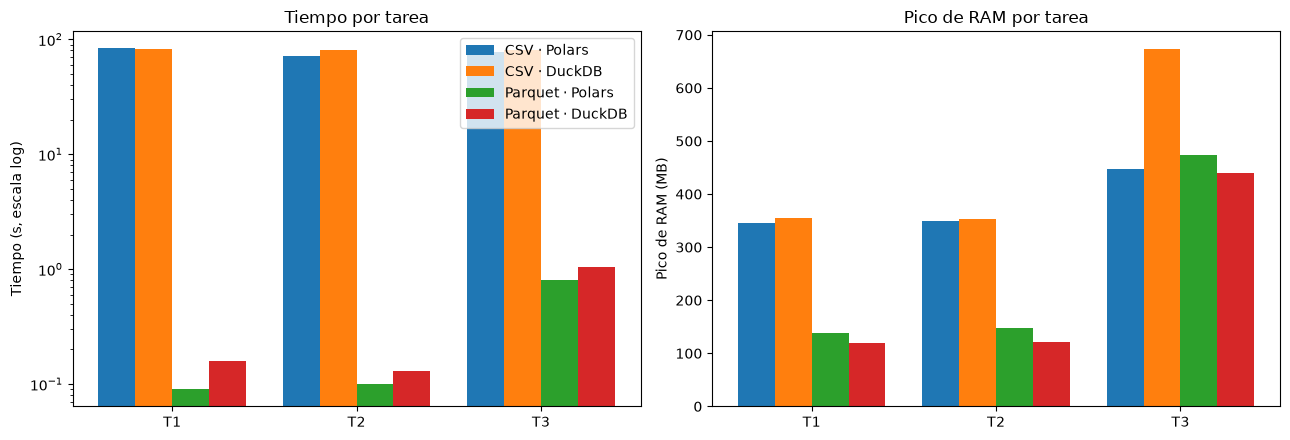

In [35]:
import numpy as np
import matplotlib.pyplot as plt

tareas = ["T1 media y varianza", "T2 filtro y conteo", "T3 agregación por cliente"]
combos = [("CSV", "Polars"), ("CSV", "DuckDB"), ("Parquet", "Polars"), ("Parquet", "DuckDB")]

def valor(tarea, formato, motor, col):
    return tabla.filter((pl.col("tarea") == tarea) & (pl.col("formato") == formato) & (pl.col("motor") == motor))[col][0]

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(tareas))
ancho = 0.2
for k, (formato, motor) in enumerate(combos):
    t = [valor(ta, formato, motor, "tiempo_s") for ta in tareas]
    r = [valor(ta, formato, motor, "ram_mb") for ta in tareas]
    ejes[0].bar(x + (k - 1.5) * ancho, t, ancho, label=f"{formato} · {motor}")
    ejes[1].bar(x + (k - 1.5) * ancho, r, ancho, label=f"{formato} · {motor}")

ejes[0].set_yscale("log")                       
ejes[0].set_ylabel("Tiempo (s, escala log)")
ejes[0].set_title("Tiempo por tarea")
ejes[1].set_ylabel("Pico de RAM (MB)")
ejes[1].set_title("Pico de RAM por tarea")
for e in ejes:
    e.set_xticks(x)
    e.set_xticklabels(["T1", "T2", "T3"])
ejes[0].legend()
plt.tight_layout()
plt.savefig("comparacion_formato_motor.png", dpi=150)
plt.show()

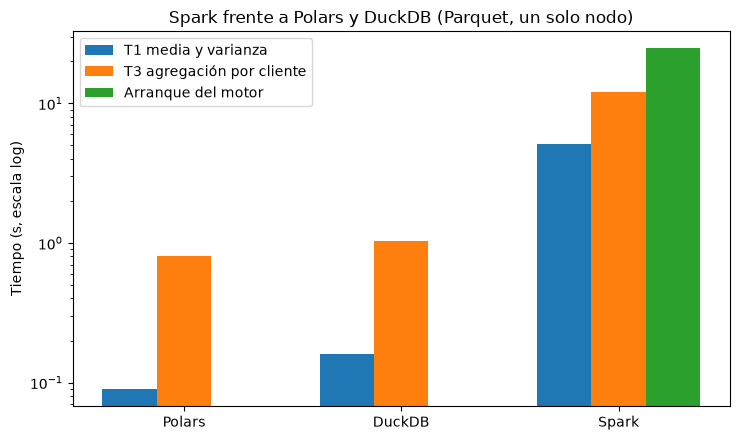

In [36]:
# Spark frente a Polars y DuckDB sobre Parquet (T1 y T3; el arranque solo aplica a Spark)
etiquetas = ["Polars", "DuckDB", "Spark"]
t1 = [valor("T1 media y varianza", "Parquet", m, "tiempo_s") for m in ["Polars", "DuckDB"]] + [5.11]
t3 = [valor("T3 agregación por cliente", "Parquet", m, "tiempo_s") for m in ["Polars", "DuckDB"]] + [12.16]
arranque = [np.nan, np.nan, 24.78]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
x = np.arange(3)
w = 0.25
ax.bar(x - w, t1, w, label="T1 media y varianza")
ax.bar(x, t3, w, label="T3 agregación por cliente")
ax.bar(x + w, arranque, w, label="Arranque del motor")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(etiquetas)
ax.set_ylabel("Tiempo (s, escala log)")
ax.set_title("Spark frente a Polars y DuckDB (Parquet, un solo nodo)")
ax.legend()
plt.tight_layout()
plt.savefig("comparacion_spark.png", dpi=150)
plt.show()

## 10. Resultados y decisiones

### Resultados completos
Mediana de 3 corridas en Parquet; una sola corrida en CSV. Cada prueba corrió en un proceso nuevo.

| Tarea | Formato | Polars | DuckDB |
|---|---|---|---|
| T1 media y varianza | CSV | 83.40 s / 345 MB | 82.07 s / 355 MB |
| T1 media y varianza | Parquet | 0.09 s / 138 MB | 0.16 s / 119 MB |
| T2 filtro y conteo | CSV | 71.83 s / 350 MB | 80.39 s / 354 MB |
| T2 filtro y conteo | Parquet | 0.10 s / 147 MB | 0.13 s / 122 MB |
| T3 agregación por cliente | CSV | 78.01 s / 448 MB | 80.46 s / 673 MB |
| T3 agregación por cliente | Parquet | 0.81 s / 473 MB | 1.04 s / 440 MB |

**El formato pesa más que el motor.** Con Parquet las tareas corren entre ~77 y ~930 veces más rápido que con CSV, según la tarea y el motor. Entre motores, sobre Parquet, la diferencia es menor que 2 veces. Esto confirma la hipótesis de la sección 3.

**Limitaciones:** las mediciones en CSV son una sola corrida. DuckDB leyó el CSV con tipos explícitos y un límite de memoria de 3 GB. Las tareas usan solo 4 columnas.

### Por qué no se usa Spark
Se probó Spark sobre el mismo Parquet, en modo local con la configuración por defecto:

| Medida | Spark | Polars |
|---|---|---|
| Arranque del motor (JVM y sesión) | 24.78 s | — |
| T1 media y varianza | 5.11 s | 0.09 s |
| T3 agregación por cliente | 12.16 s | 0.81 s |
| RAM | ≈1.4 GB (168 MB de Python + 1 271 MB de la JVM) | 138 a 473 MB |

El solo arranque de Spark tardó más de 30 veces lo que Polars tarda en la tarea 3 completa. Con 5.5 millones de filas en una sola máquina, la sobrecarga de la JVM supera cualquier beneficio de distribuir el trabajo. Es una corrida sin ajuste de configuración, y con un clúster o con datos mucho mayores el resultado podría cambiar.

### Elección del motor: Polars
Criterio: menor tiempo y menor pico de RAM, con la restricción de que el trabajo cabe en la RAM disponible (~3.9 GiB).
- **La RAM no es el factor limitante.** Con Parquet, todas las pruebas de ambos motores quedaron por debajo de 480 MB.
- **Por eso decide el tiempo.** Polars fue más rápido en las 3 tareas sobre Parquet (0.09 frente a 0.16 s, 0.10 frente a 0.13 s y 0.81 frente a 1.04 s).
- **DuckDB usó 19 a 33 MB menos de RAM en Parquet.** Es una diferencia sin impacto práctico en este equipo.
- La conversión a Parquet y la inspección del plan (`explain()`) se hicieron con Polars.


### Ruta de optimización de la línea base a la mejor solución

| # | Optimización | Técnica de clase | Antes | Después |
|---|---|---|---|---|
| 0 | Descargar solo `train_data.csv` y `train_labels.csv`, en `/tmp` | — | 50.31 GB de competencia | ≈15.3 GiB en disco (zip de 6.67 GB; 207 s) |
| 1 | Leer por lotes en lugar de cargar todo | Evaluación perezosa y *streaming* | Cargar todo: ≈8.3 GB estimados, más de lo que cabe | Conteo de filas en CSV: 81.75 s con 4 261 MB |
| 2 | Convertir CSV a Parquet con esquema explícito | Almacenamiento columnar | 15.27 GiB | 5.76 GiB (−62.3 %), en 105.34 s y 654 MB |
| 3 | Leer solo las columnas y filas necesarias (*pushdown*) | Almacenamiento columnar y plan de ejecución | T2 en CSV: 71.83 s y 350 MB | T2 en Parquet: 0.10 s y 147 MB |
| 4 | Guardar n, Σx y Σx² de cada columna | Estadísticos con datos intermedios | Releer el archivo en cada consulta | Respuesta en 27 ms; costo único de 32.74 s |
| 5 | Elegir el motor con medición | Comparación experimental | DuckDB: 1.04 s en T3 | Polars: 0.81 s en T3 |
| 6 | Descartar Spark | Comparación experimental | — | Solo el arranque tomó 24.78 s |

**Mejora final (Polars con Parquet frente a Polars con CSV):** T1 de 83.40 s a 0.09 s; T2 de 71.83 s a 0.10 s; T3 de 78.01 s a 0.81 s.

## 11. Resultados finales y Conclusiones

**Respuesta a la pregunta de investigación:** la mejor combinación de las probadas es **Parquet con Polars** (lectura perezosa y *streaming*): agrega por cliente los 5.5 millones de filas en 0.81 s con un pico de 473 MB de RAM, frente a 78.01 s y 448 MB con CSV.

1. **El formato pesa más que el motor.** Con Parquet las tareas fueron entre ~77 y ~930 veces más rápidas que con CSV; entre Polars y DuckDB la diferencia fue menor que 2 veces.
2. **La RAM no fue el factor limitante** una vez en Parquet: todas las pruebas quedaron por debajo de 480 MB, frente a ~3.9 GiB disponibles.
3. **El ahorro viene de leer menos:** *pushdown* de proyección (3 de 190 columnas) y de filtro, más la metadata de Parquet, que responde el conteo, el mínimo, el máximo y los nulos sin leer datos.
4. **Los datos intermedios sirven para estadísticos repetidos.** Calcularlos cuesta una pasada (32.74 s para 186 columnas); después, la media y la varianza se responden en milisegundos. No ganan sobre un cálculo directo en Parquet de una sola columna.
5. **Spark no se justifica en este caso:** solo su arranque (24.78 s) superó con creces el tiempo total de Polars en las tres tareas.

Los resúmenes públicos de la competencia describen optimizaciones de memoria orientadas al entorno de Kaggle y a maximizar el puntaje del modelo, pero no comparan formatos ni motores midiendo tiempo y RAM. Este trabajo aporta esa comparación sistemática en una máquina de 8 GB, con las mismas tareas y mediciones en procesos aislados.

### Limitaciones
- Las mediciones en CSV son una sola corrida; las de Parquet, medianas de 3.
- Las tareas usan 4 de las 188 variables, en un solo equipo.
- El Parquet no se reorganizó por fecha, así que el filtro por fecha no puede saltar grupos de filas.
- Spark se probó sin ajustar su configuración.
- No se analizó el modelo de incumplimiento: la clase negativa fue submuestreada en la competencia y la proporción de `target` no representa la tasa real.